# Interest Classifier — is this news worth looking at?

**Goal:** given a news headline, predict `Interest`:
- **1** → about an Indian large-cap company or a big market driver (crude, gold, RBI, inflation, budget, FII flows)
- **0** → penny stocks, unrelated, or non-business stuff (IFSC codes, CNG prices in Agra, ...)

**Where the labels come from:** Gemini labelled all ~10k rows (`gemini_ner_annotator.py`). So this model is learning to *copy Gemini's judgement* —
cheaply, locally, and forever. Its score can never really beat "how well it agrees with Gemini", and wherever Gemini was wrong, the model learns that mistake too.

**Plan of this notebook**
1. Load data, use **headlines only** (reason below)
2. Split into train / validation / test
3. Three models, from dumbest to smartest:
   - *Always say 1* — the "do nothing" score to beat
   - *TF-IDF + Logistic Regression* — a fast word-counting model
   - *FinBERT fine-tuned* — a transformer that already knows finance language, retrained for our yes/no question
4. Compare, look at the mistakes, test on Reddit posts, save the best model

In [1]:
import os, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "No GPU found - run this with the WSL stock_env kernel"
print("GPU:", torch.cuda.get_device_name(0))

PROJECT_ROOT = os.path.abspath(".")
DATA_PATH = os.path.join(PROJECT_ROOT, "Datasets", "financial_news_ner_annotated_clean.csv")
MODEL_DIR = os.path.join(PROJECT_ROOT, "Models", "interest_classifier")

/home/arnav/stock_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 5050 Laptop GPU


## 1. Load the data

**Why headlines only, not `Article`?** For ~91% of rows, `Article` is just the headline with the website name glued on the end
(e.g. `"...IFSC Code, AURANGABADMoneycontrol.com"`). If the model sees that, it can cheat: it might learn *"Moneycontrol.com at the end → probably 0"*
instead of learning what the news is about. That works on this dataset and fails on new data. This kind of hidden shortcut is called **leakage** — always look out for it.

We also keep **Reddit rows aside**. The model trains on news only, and at the end we check how it does on Reddit text it has never seen —
useful for our Reddit plans.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df.dropna(subset=["Headlines", "Interest"])
df["text"] = df["Headlines"].astype(str).str.strip()
df["Interest"] = df["Interest"].astype(int)
df = df.drop_duplicates(subset="text").reset_index(drop=True)

is_reddit = df["Category"].eq("retail_sentiment")
news_df, reddit_df = df[~is_reddit].reset_index(drop=True), df[is_reddit].reset_index(drop=True)

print(f"News rows: {len(news_df):,}   Reddit rows (kept aside): {len(reddit_df):,}")
print("\nShare of each label in news:")
print(news_df["Interest"].value_counts(normalize=True).round(3).rename({1: "1 (interesting)", 0: "0 (not)"}))

News rows: 9,815   Reddit rows (kept aside): 291

Share of each label in news:
Interest
1 (interesting)    0.772
0 (not)            0.228
Name: proportion, dtype: float64


## 2. Split: train 70% / validation 15% / test 15%

- **Train** — the model learns from this
- **Validation** — we use it to make choices (which epoch was best, which cut-off to use)
- **Test** — touched **once**, at the very end, to get an honest score. If we kept tuning on test, we'd slowly fit to it and fool ourselves.

`stratify` keeps the 1s-vs-0s ratio the same in all three parts.

In [3]:
train_df, temp_df = train_test_split(news_df, test_size=0.30, stratify=news_df["Interest"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["Interest"], random_state=SEED)
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part):5,} rows, {part['Interest'].mean():.1%} are 1")

train: 6,870 rows, 77.2% are 1
val  : 1,472 rows, 77.2% are 1
test : 1,473 rows, 77.2% are 1


## 3. How we score models

About **76% of headlines are 1**. So a model that blindly says "1" every time already gets 76% accuracy — while being useless.
That's why **accuracy alone lies here**. We also look at:

- **Precision (for 1)** — of everything we *kept*, how much was truly interesting?
- **Recall (for 1)** — of all truly interesting news, how much did we *keep*?
- **Macro F1** — F1 of class 1 and F1 of class 0, averaged. It only gets high if the model is good at **both** keeping good news and dropping junk. This is our main score.
- **ROC AUC** — how well the model *ranks* interesting above non-interesting, whatever cut-off we pick (0.5 = coin toss, 1.0 = perfect)

**Cut-off (threshold):** models give a probability, like 0.63. By default ≥ 0.5 means "1", but 0.5 isn't magic.
We try every cut-off on the **validation** set and keep the one with the best macro F1.

In [4]:
def scores(y_true, prob, threshold, name):
    pred = (prob >= threshold).astype(int)
    return {
        "model": name,
        "threshold": round(threshold, 2),
        "accuracy": accuracy_score(y_true, pred),
        "precision_1": precision_score(y_true, pred, zero_division=0),
        "recall_1": recall_score(y_true, pred, zero_division=0),
        "f1_1": f1_score(y_true, pred, zero_division=0),
        "f1_0": f1_score(y_true, pred, pos_label=0, zero_division=0),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob),
    }

def best_threshold(y_true, prob):
    cutoffs = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_true, (prob >= t).astype(int), average="macro", zero_division=0) for t in cutoffs]
    return float(cutoffs[int(np.argmax(f1s))])

y_train, y_val, y_test = train_df["Interest"].values, val_df["Interest"].values, test_df["Interest"].values
results = []

## 4. Model 0 — "always say 1" (the floor)
Any real model must clearly beat this, otherwise it learned nothing.

In [5]:
results.append(scores(y_test, np.ones(len(y_test)), 0.5, "Always 1"))
pd.DataFrame(results).round(3)

,model,threshold,accuracy,precision_1,recall_1,f1_1,f1_0,macro_f1,roc_auc
0,Always 1,0.5,0.772,0.772,1.0,0.871,0.0,0.436,0.5


## 5. Model 1 — TF-IDF + Logistic Regression

**TF-IDF** turns each headline into a long list of numbers: one slot per word (and per 2-word phrase like *"hdfc bank"*),
with bigger values for words that are rare across headlines (and so more telling). **Logistic regression** then learns one weight per word:
positive weight pushes towards 1, negative towards 0.

It knows nothing about meaning or word order — but it's fast, easy to understand, and often surprisingly strong. Always build one of these first:
if the fancy model can't beat it, the fancy model isn't worth it.

`class_weight="balanced"` makes mistakes on the rarer class (0) count more, so the model doesn't just lean towards 1.

In [6]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["text"])   # learn vocabulary from TRAIN only
X_val, X_test = tfidf.transform(val_df["text"]), tfidf.transform(test_df["text"])

logreg = LogisticRegression(max_iter=3000, class_weight="balanced", C=4.0)
logreg.fit(X_train, y_train)

lr_th = best_threshold(y_val, logreg.predict_proba(X_val)[:, 1])
lr_test_prob = logreg.predict_proba(X_test)[:, 1]
results.append(scores(y_test, lr_test_prob, lr_th, "TF-IDF + LogReg"))
pd.DataFrame(results).round(3)

,model,threshold,accuracy,precision_1,recall_1,f1_1,f1_0,macro_f1,roc_auc
0,Always 1,0.50,0.772,0.772,1.000,0.871,0.00,0.436,0.500
1,TF-IDF + LogReg,0.41,0.860,0.887,0.938,0.912,0.66,0.786,0.912


**Peek inside:** which words push hardest towards each label? If these look sensible, the model learned something real.
If you see junk like website names here, that's a leakage warning.

In [7]:
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(logreg.coef_[0])
print("Pushes towards 1 (interesting):", ", ".join(words[order[-25:]][::-1]))
print("\nPushes towards 0 (not):        ", ", ".join(words[order[:25]]))

Pushes towards 1 (interesting): reliance, rbi, tcs, infosys, oil, nifty, sbi, jio, bank, tata, hdfc, banks, hdfc bank, gold, ril, rupee, rate, says, to, crude, adani, amid, sensex, may, reliance industries

Pushes towards 0 (not):         ltd, bengaluru, your, co, reliance home, how to, ipo, price, wedding, anant, inside, netflix, ifsc code, funding, direct, limited, corporate, circuit, how, smart, personal, video, visits, plans, india as


## 6. Model 2 — fine-tuning FinBERT

**FinBERT** is a BERT model that was pre-trained on lots of financial text, so it already "gets" finance language and word order
(*"Reliance beats estimates"* vs *"estimates beat... Reliance?"*). Its original job was sentiment (positive/negative/neutral).
We **throw away its last layer** (the sentiment part) and put a fresh yes/no layer on top, then train the whole thing a little on our data.
This is called **fine-tuning** — reusing a model's knowledge for a new task, so we need far less data than training from scratch.

First: how long are headlines in tokens (word-pieces)? That decides `MAX_LEN` — longer = slower, too short = cut-off text.

In [8]:
MODEL_NAME = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

lengths = [len(tokenizer.encode(t)) for t in train_df["text"]]
print("Tokens per headline - median:", int(np.median(lengths)), "| 99th percentile:", int(np.percentile(lengths, 99)), "| max:", max(lengths))
MAX_LEN = 64  # covers ~99%+ of headlines

Tokens per headline - median: 20 | 99th percentile: 36 | max: 63


In [9]:
class HeadlineDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding="max_length", return_tensors="pt")
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {"input_ids": self.enc["input_ids"][i], "attention_mask": self.enc["attention_mask"][i], "labels": self.labels[i]}

BATCH_SIZE = 32
train_loader = DataLoader(HeadlineDataset(train_df["text"], y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(HeadlineDataset(val_df["text"], y_val), batch_size=128)
test_loader = DataLoader(HeadlineDataset(test_df["text"], y_test), batch_size=128)

**Training setup, in plain words**
- **Learning rate 2e-5** — tiny steps. FinBERT already knows a lot; big steps would wreck that knowledge.
- **Warm-up then slow-down** — start with even smaller steps for the first 10%, then shrink the step size to zero by the end. Keeps early training stable.
- **Class weights in the loss** — same idea as `class_weight="balanced"` above: mistakes on the rarer 0s cost more.
- **bfloat16** — does the maths in a lighter number format. ~2x faster on your RTX 5050, no real loss in quality.
- **Keep the best epoch** — after each pass over the data we check validation macro F1 and remember the best version. Later epochs can start memorising training data (*overfitting*).

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True,   # drop the 3-class sentiment head, add a new 2-class one
    id2label={0: "not_interest", 1: "interest"}, label2id={"not_interest": 0, "interest": 1},
).to(DEVICE)

EPOCHS, LR = 4, 2e-5
counts = np.bincount(y_train)
class_weights = torch.tensor(len(y_train) / (2 * counts), dtype=torch.float).to(DEVICE)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
print("Class weights (0, 1):", class_weights.cpu().numpy().round(2))

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 44/201 [00:00<00:00, 439.12it/s]

Loading weights:  47%|████▋     | 94/201 [00:00<00:00, 465.32it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 700.84it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key               | Status   |                                                                                       
------------------+----------+---------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Class weights (0, 1): [2.19 0.65]


In [11]:
def predict_probs(loader):
    model.eval()
    probs = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        for batch in loader:
            logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
            probs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(probs).numpy()

history, best_f1, best_state = [], -1.0, None
for epoch in range(1, EPOCHS + 1):
    model.train()
    start, running = time.time(), 0.0
    for batch in train_loader:
        optimizer.zero_grad()
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
        loss = loss_fn(logits.float(), batch["labels"].to(DEVICE))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # stops rare huge updates
        optimizer.step(); scheduler.step()
        running += loss.item()

    val_prob = predict_probs(val_loader)
    val_f1 = f1_score(y_val, (val_prob >= 0.5).astype(int), average="macro")
    history.append({"epoch": epoch, "train_loss": running / len(train_loader), "val_macro_f1": val_f1})
    print(f"epoch {epoch}: train loss {running / len(train_loader):.4f} | val macro F1 {val_f1:.4f} | {time.time() - start:.0f}s")
    if val_f1 > best_f1:
        best_f1, best_state = val_f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
print("Kept epoch with val macro F1 =", round(best_f1, 4))

epoch 1: train loss 0.5408 | val macro F1 0.8032 | 42s


epoch 2: train loss 0.3218 | val macro F1 0.8180 | 25s


epoch 3: train loss 0.2060 | val macro F1 0.8208 | 26s


epoch 4: train loss 0.1358 | val macro F1 0.8250 | 28s


Kept epoch with val macro F1 = 0.825


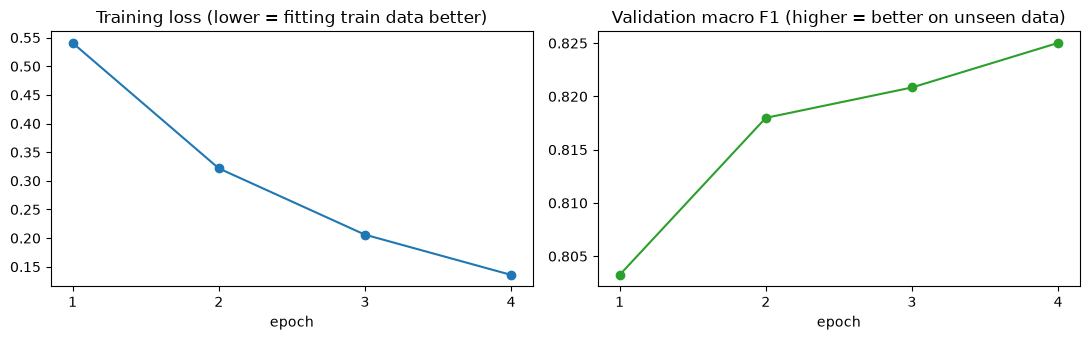

In [12]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h["epoch"], h["train_loss"], marker="o"); ax[0].set_title("Training loss (lower = fitting train data better)")
ax[1].plot(h["epoch"], h["val_macro_f1"], marker="o", color="tab:green"); ax[1].set_title("Validation macro F1 (higher = better on unseen data)")
for a in ax: a.set_xlabel("epoch"); a.set_xticks(h["epoch"])
plt.tight_layout(); plt.show()

In [13]:
bert_th = best_threshold(y_val, predict_probs(val_loader))
bert_test_prob = predict_probs(test_loader)
results.append(scores(y_test, bert_test_prob, bert_th, "FinBERT fine-tuned"))
results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,threshold,accuracy,precision_1,recall_1,f1_1,f1_0,macro_f1,roc_auc
model,,,,,,,,
Always 1,0.50,0.772,0.772,1.000,0.871,0.000,0.436,0.500
TF-IDF + LogReg,0.41,0.860,0.887,0.938,0.912,0.660,0.786,0.912
FinBERT fine-tuned,0.34,0.880,0.909,0.938,0.923,0.721,0.822,0.923


## 7. Where does it go wrong?

Numbers tell you *how much* it's wrong; looking at mistakes tells you *why*. Two kinds:
- **Kept junk (false positive):** model said 1, Gemini said 0
- **Dropped good news (false negative):** model said 0, Gemini said 1

While reading, ask: is the **model** wrong, or was **Gemini's label** questionable? If many mistakes are really label mistakes, the fix is better labels, not a bigger model.

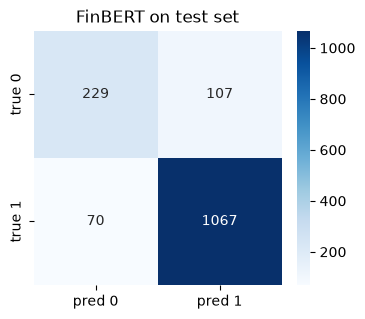

Kept junk (model 1, label 0):


,text,Company,prob
8728,"Bessent Axing 20-Year Treasury May Send Yields Higher, BNP Warns",BNP Paribas,0.996
5118,FACE appoints ex-RBI executive Manoranjan Mishra as independent director,NaN,0.995
7447,"TMC leader Aroop Biswas writes to HDFC to freeze party's bank account, cites leadership dispute",HDFC Bank,0.995
3230,"Mint Explainer: Why Sebi halted trading in LS Industries, Pacheli Industrial Finance",LS Industries,0.994
5013,JD Cables IPO: 20 investors including HDFC Bank acquire Rs 27 crore shares via anchor book,JD Cables,0.994
9352,"Bitcoin recovers above $77,300 despite hawkish Fed, ETF outflows; What’s next?",NaN,0.994
4918,"Promoter offloads 5% stake in Aditya Vision, SBI sells 0.63% shares in Vikran Engineering",Aditya Vision,0.993
1805,"Exclusive: AGS Transact Technologies eye contracts with SBI, Union Bank of India and PNB for 18,000 ATMs...",AGS Transact Technologies,0.993
1702,"From Kardashians to Samsung chief, celebs to attend Ambani wedding",Reliance Industries,0.993
9766,"Passive investing is no longer just Nifty, Sensex; index choice matters as options multiply",NaN,0.993


Dropped good news (model 0, label 1):


,text,Company,prob
2448,"Multiples PE-backed Veritas Finance plans over Rs 3,000 crore IPO",Veritas Finance,0.007
293,"Entero Healthcare Solutions IPO Date: Check Issue Date, Price, Lot size, Subscription, News and Details - Moneycontrol",Entero Healthcare Solutions,0.007
2404,Trent expands into beauty retail with new Zudio format: Report,Trent,0.008
2261,"Flipkart Big Billion Days 2024 sale date revealed: Check out top offers, bank discounts and more",Flipkart,0.008
7021,"Sitharaman's video fake, created with AI, clarifies PIB; warns against fraudulent investment scheme claims — Details",NaN,0.009
3443,'Silly old programs paraded as AI': Narayana Murthy slams AI hype in India,Infosys,0.009
2489,"Waaree Energies IPO Date: Check Issue Date, Price, Lot size, Subscription, News and Details - Moneycontrol",Waaree Energies,0.009
1598,"Emcure Pharmaceuticals IPO day 2: GMP, subscription status, review to allotment date. Apply or not?",Emcure Pharmaceuticals,0.010
6478,TCS NQT admit card 2026 out at tcsion.com: Download hall ticket for April exam cycle; direct link here,Tata Consultancy Services,0.010
9114,"Stock Price, Market Indices, Price, Stock Performance & Comparison",NaN,0.011


In [14]:
pred = (bert_test_prob >= bert_th).astype(int)
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4, 3.3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"])
plt.title("FinBERT on test set"); plt.show()

mistakes = test_df.assign(prob=bert_test_prob.round(3), pred=pred)
pd.set_option("display.max_colwidth", 120)
print("Kept junk (model 1, label 0):")
display(mistakes[(mistakes.pred == 1) & (mistakes.Interest == 0)].sort_values("prob", ascending=False)[["text", "Company", "prob"]].head(12))
print("Dropped good news (model 0, label 1):")
display(mistakes[(mistakes.pred == 0) & (mistakes.Interest == 1)].sort_values("prob")[["text", "Company", "prob"]].head(12))

## 8. Does it work on Reddit?

The model never saw Reddit. Reddit titles look nothing like news headlines (*"is my portfolio too diversified?"*, memes, slang),
so expect a drop. How big the drop is tells us whether we can reuse this model to filter Reddit comments later.

In [15]:
reddit_loader = DataLoader(HeadlineDataset(reddit_df["text"], reddit_df["Interest"].values), batch_size=128)
y_reddit = reddit_df["Interest"].values
reddit_results = pd.DataFrame([
    scores(y_reddit, logreg.predict_proba(tfidf.transform(reddit_df["text"]))[:, 1], lr_th, "TF-IDF + LogReg"),
    scores(y_reddit, predict_probs(reddit_loader), bert_th, "FinBERT fine-tuned"),
]).set_index("model").round(3)
print(f"Reddit rows: {len(reddit_df)} ({y_reddit.mean():.0%} are 1 - note: the opposite balance from news!)")
reddit_results

Reddit rows: 291 (25% are 1 - note: the opposite balance from news!)


,threshold,accuracy,precision_1,recall_1,f1_1,f1_0,macro_f1,roc_auc
model,,,,,,,,
TF-IDF + LogReg,0.41,0.529,0.322,0.795,0.458,0.584,0.521,0.747
FinBERT fine-tuned,0.34,0.753,0.504,0.822,0.625,0.815,0.720,0.863


## 9. Save the model and use it on new headlines

In [16]:
os.makedirs(MODEL_DIR, exist_ok=True)
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)
with open(os.path.join(MODEL_DIR, "interest_config.json"), "w") as f:
    json.dump({"threshold": bert_th, "max_len": MAX_LEN, "base_model": MODEL_NAME, "input": "Headlines only",
               "test_scores": results_df.loc["FinBERT fine-tuned"].to_dict(),
               "reddit_scores": reddit_results.loc["FinBERT fine-tuned"].to_dict()}, f, indent=2)
print("Saved to", MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.79s/it]

Writing model shards: 100%|██████████| 1/1 [00:03<00:00,  3.79s/it]

Saved to /mnt/c/Users/arnav/OneDrive/Documents/Self_Apps/Stock-Market-Prediction/Models/interest_classifier


In [17]:
def predict_interest(headlines, threshold=bert_th):
    enc = tokenizer(list(headlines), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
    model.eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        prob = torch.softmax(model(**enc).logits.float(), dim=-1)[:, 1].cpu().numpy()
    return pd.DataFrame({"headline": headlines, "prob_interest": prob.round(3), "interest": (prob >= threshold).astype(int)})

predict_interest([
    "Reliance Industries Q2 net profit jumps 12%, beats street estimates",
    "RBI keeps repo rate unchanged at 6.5%, maintains withdrawal of accommodation stance",
    "Brent crude surges 4% after OPEC+ announces surprise output cut",
    "Petrol price in Agra today, check latest rates",
    "Small-cap XYZ Textiles hits upper circuit for 5th straight session",
    "Best SIP plans for beginners in 2026",
])

,headline,prob_interest,interest
0,"Reliance Industries Q2 net profit jumps 12%, beats street estimates",0.993,1
1,"RBI keeps repo rate unchanged at 6.5%, maintains withdrawal of accommodation stance",0.996,1
2,Brent crude surges 4% after OPEC+ announces surprise output cut,0.993,1
3,"Petrol price in Agra today, check latest rates",0.042,0
4,Small-cap XYZ Textiles hits upper circuit for 5th straight session,0.010,0
5,Best SIP plans for beginners in 2026,0.008,0


## 10. Things to try yourself 🧠

Hints, not answers:
1. **Does `Article` really add nothing?** Strip the website name from the end of `Article` and feed `headline + article` to the TF-IDF model. Does macro F1 move? Why might it?
2. **Is the 76/24 split hurting class 0?** Look at `f1_0` vs `f1_1`. Try training *without* class weights and compare. Which one would you pick if dropping good news is worse than keeping some junk?
3. **Time matters in finance.** We split randomly, so the model saw 2026 headlines during training and was tested on 2024 ones. Re-split by date (train on older, test on newest). Does the score drop? Which split is the honest one for a model that will run on *tomorrow's* news?
4. **The Reddit gap.** What would you need to make this model work on Reddit text? (Think: where would the labels come from?)
5. **How good can it even get?** Pick 100 test headlines, label them yourself without looking, and check how often you agree with Gemini. That's roughly the ceiling for this model.